In [29]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import Annotated, TypedDict
from dotenv import load_dotenv

load_dotenv()

llm = ChatGoogleGenerativeAI(
    model = "gemini-3.5-flash-lite"
)

In [30]:
class JokeState(TypedDict):
    topic : str
    joke : str
    explanation : str
    

In [31]:
def generate_joke(state: JokeState):
    topic = state['topic']

    prompt = f"Generate a Joke on the topic of '{topic}'"
    response = llm.invoke(prompt).text

    return {'joke' : response}

In [32]:
def explain_joke(state: JokeState):
    topic = state['topic']
    joke = state['joke']

    prompt = f"explain given Joke  '{joke}' on the topic of '{topic}'"
    response = llm.invoke(prompt).text

    return {'explanation' : response}

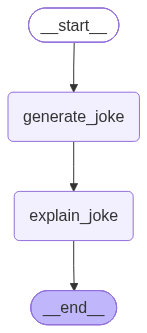

In [33]:
checkpointer = MemorySaver()
graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('explain_joke', explain_joke)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'explain_joke')
graph.add_edge('explain_joke', END)

workflow = graph.compile(checkpointer=checkpointer)
workflow


In [40]:
thread_id = 1

config1 = {'configurable' : {'thread_id' : thread_id}}

initial_state = {
    'topic' : "Java"
}

workflow.invoke(initial_state, config=config1)

KeyboardInterrupt: 

In [35]:
thread_id = 2

config2 = {'configurable' : {'thread_id' : thread_id}}

initial_state = {
    'topic' : "Pizza"
}

workflow.invoke(initial_state, config=config2)

{'topic': 'Pizza',
 'joke': 'Why does pizza make a terrible secret agent?\n\nBecause it always gets found out by the crust!',
 'explanation': 'Here is an explanation of the joke, broken down by its connection to the topic of **pizza**:\n\n### The Joke:\n> *"Why does pizza make a terrible secret agent? Because it always gets found out by the crust!"*\n\n---\n\n### The Explanation:\n\n1. **The Setup (Secret Agent):** \n   A secret agent is a spy whose main job is to remain hidden, blend in, and **not** get caught. \n\n2. **The Twist (Pizza Terminology):** \n   The punchline plays on a double meaning of the word **"crust"**:\n   * **In Crime/Spy Fiction:** To "get found out" means to get caught, and criminals are often exposed because they leave behind physical evidence (like fingerprints or clues). In slang, criminals or suspects are sometimes called "crusts" or "low-lifes" (though less common, the word play sets up the next point).\n   * **In Baking/Pizza:** The "crust" is the outer edg

In [36]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'Java', 'joke': "Why do Java developers wear glasses? \n\nBecause they can't **C#**.", 'explanation': 'This classic programming joke relies on a **pun** involving the names of two major programming languages: **Java** and **C#** (pronounced "C-sharp").\n\nHere is the breakdown of why it\'s funny:\n\n1. **The Setup ("Java developers wear glasses"):** \n   The joke starts with a common stereotype that programmers have poor eyesight and need to wear glasses from staring at computer screens all day.\n\n2. **The Punchline ("Because they can\'t C#"):** \n   * **Literal meaning:** "C#" sounds exactly like the phrase **"see sharp"** (as in, having sharp, clear vision). So, visually, a Java developer wears glasses because they *cannot see sharply*.\n   * **Programming meaning:** **C#** (developed by Microsoft) is the main rival to **Java** (developed by Oracle/Sun). Both are object-oriented programming languages used for building similar types of software. \n\n**I

In [39]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'Java', 'joke': "Why do Java developers wear glasses? \n\nBecause they can't **C#**.", 'explanation': 'This classic programming joke relies on a **pun** involving the names of two major programming languages: **Java** and **C#** (pronounced "C-sharp").\n\nHere is the breakdown of why it\'s funny:\n\n1. **The Setup ("Java developers wear glasses"):** \n   The joke starts with a common stereotype that programmers have poor eyesight and need to wear glasses from staring at computer screens all day.\n\n2. **The Punchline ("Because they can\'t C#"):** \n   * **Literal meaning:** "C#" sounds exactly like the phrase **"see sharp"** (as in, having sharp, clear vision). So, visually, a Java developer wears glasses because they *cannot see sharply*.\n   * **Programming meaning:** **C#** (developed by Microsoft) is the main rival to **Java** (developed by Oracle/Sun). Both are object-oriented programming languages used for building similar types of software. \n\n**